In [1]:
from functions import*

df = pd.read_excel("../data/raw/NIMS_FATIGUE.xlsx")   # use read_excel(...) if it's .xlsx
print(df.shape)
df.head()

(2793, 20)


,Heat,Testing Material,DS No. PDF,Reduction Ratio,dA,dB,dC,Normalizing temp,Quenching temp,Tempering temp,Upper yield stress,0.2% proof stress,Tensile strength,True fracture stress,Elongation,Reduction of area,Vickers hardness,Type of test,σa,Nf
0,A,S25C,1,825,0.07,0.02,0.04,885.0,NaN,NaN,354.0,333,473,961.0,0.4,0.64,138,Rotating bending,290,39800.0
1,A,S25C,1,825,0.07,0.02,0.04,885.0,NaN,NaN,354.0,333,473,961.0,0.4,0.64,138,Rotating bending,290,68400.0
2,A,S25C,1,825,0.07,0.02,0.04,885.0,NaN,NaN,354.0,333,473,961.0,0.4,0.64,138,Rotating bending,280,109000.0
3,A,S25C,1,825,0.07,0.02,0.04,885.0,NaN,NaN,354.0,333,473,961.0,0.4,0.64,138,Rotating bending,280,123000.0
4,A,S25C,1,825,0.07,0.02,0.04,885.0,NaN,NaN,354.0,333,473,961.0,0.4,0.64,138,Rotating bending,270,115000.0


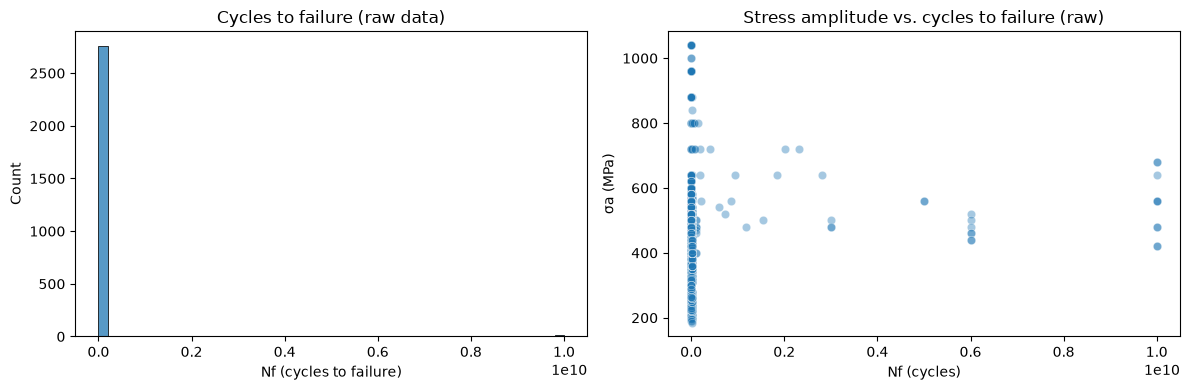

In [5]:
from functions import*

df = pd.read_excel("../data/raw/NIMS_FATIGUE.xlsx")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))


# histogram of the raw data
sns.histplot(df["Nf"], bins=50, ax=axes[0])
axes[0].set_title("Cycles to failure (raw data)")
axes[0].set_xlabel("Nf (cycles to failure)")

# how much stress vs. cycles to failure
sns.scatterplot(data=df, x="Nf", y="σa", alpha=0.4, ax=axes[1])
axes[1].set_title("Stress amplitude vs. cycles to failure (raw)")
axes[1].set_xlabel("Nf (cycles)")
axes[1].set_ylabel("σa (MPa)")

plt.tight_layout()
plt.savefig("../figures/raw_target.png", dpi=150)
plt.show()

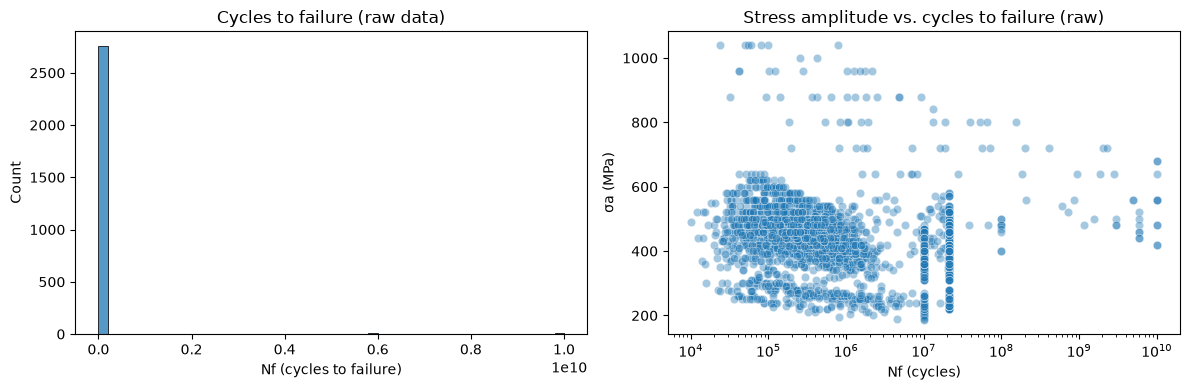

In [6]:
from functions import*

df = pd.read_excel("../data/raw/NIMS_FATIGUE.xlsx")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))


# histogram of the raw data
sns.histplot(df["Nf"], bins=50, ax=axes[0])
axes[0].set_title("Cycles to failure (raw data)")
axes[0].set_xlabel("Nf (cycles to failure)")

# how much stress vs. cycles to failure
sns.scatterplot(data=df, x="Nf", y="σa", alpha=0.4, ax=axes[1])
axes[1].set_title("Stress amplitude vs. cycles to failure (raw)")
axes[1].set_xlabel("Nf (cycles)")
axes[1].set_ylabel("σa (MPa)")
axes[1].set_xscale("log") #added to change the x-axis so data can be seen clearer
hue = df["Testing Material"]

plt.tight_layout()
plt.savefig("../figures/raw_target_log_xaxis.png", dpi=150)
plt.show()

count    2.793000e+03
mean     6.945012e+07
std      6.936210e+08
min      1.010000e+04
25%      1.680000e+05
50%      5.260000e+05
75%      1.000000e+07
max      1.000000e+10
Name: Nf, dtype: float64
Skewness: 12.479357092135732
Zeros or negatives: 0


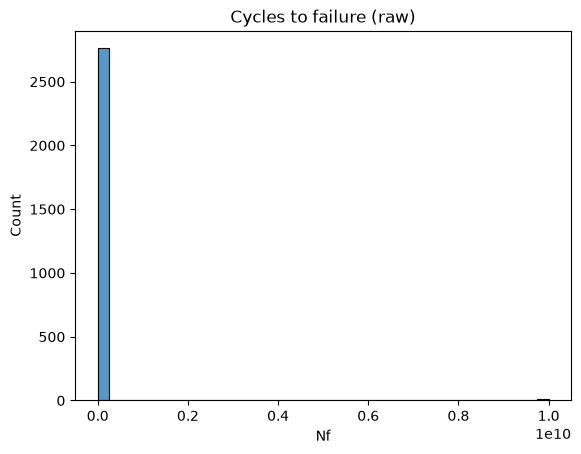

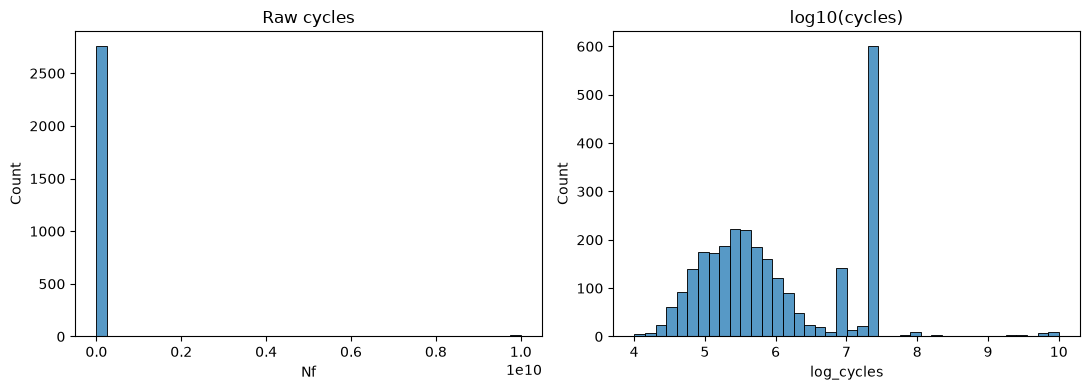

Skewness after log: 0.6973304730598687


In [9]:
from functions import*
df = pd.read_excel("../data/raw/NIMS_FATIGUE.xlsx")

target = "Nf"   

df["log_Nf"] = np.log10(df[target]) 

print(df[target].describe())
print("Skewness:", df[target].skew())
print("Zeros or negatives:", (df[target] <= 0).sum())

sns.histplot(df[target], bins=40)
plt.title("Cycles to failure (raw)")
plt.show()

df["log_cycles"] = np.log10(df[target])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df[target], bins=40, ax=axes[0]).set_title("Raw cycles")
sns.histplot(df["log_cycles"], bins=40, ax=axes[1]).set_title("log10(cycles)")
plt.tight_layout()
plt.savefig("../figures/target_distribution.png", dpi=150)
plt.show()

print("Skewness after log:", df["log_cycles"].skew())